
# Lab 7: Explainable AI, Adversarial AI and Advanced Applications

## Introduction

Artificial Intelligence models can make predictions with high accuracy, but understanding how they make those predictions is equally important. Explainable AI (XAI) helps us understand the decisions made by machine learning and deep learning models.

Adversarial AI studies how small, carefully designed changes to input data can affect the predictions of an AI model. These changes are called adversarial perturbations.

This laboratory focuses on Explainable AI, adversarial attacks, Convolutional Neural Networks (CNNs), image classification, and dimensionality reduction using PCA.

## Topics Covered

1. **ResNet-Based Image Classification**
   - Introduction to CNN-based image classification.
   - Understanding pretrained ResNet models.
   - Loading images and generating predictions.
   - Understanding transfer learning.

2. **Explainable AI Using Grad-CAM**
   - Introduction to model interpretability.
   - Understanding Class Activation Maps.
   - Generating Grad-CAM heatmaps.
   - Visualizing important image regions.

3. **Adversarial AI Using FGSM**
   - Understanding adversarial attacks.
   - Introduction to Fast Gradient Sign Method.
   - Generating adversarial images.
   - Comparing predictions before and after an attack.

4. **PCA for Dimensionality Reduction**
   - Understanding high-dimensional datasets.
   - Introduction to Principal Component Analysis.
   - Reducing dimensions.
   - Visualizing data in two dimensions.

5. **Mini Project: Explainable Image Classification**
   - Performing image classification.
   - Explaining predictions using Grad-CAM.
   - Testing model robustness using FGSM.
   - Presenting the results through visualizations.

## Learning Objectives

- Understand CNN-based image classification.
- Implement a pretrained ResNet model.
- Explain image classification decisions using Grad-CAM.
- Understand and implement adversarial attacks using FGSM.
- Evaluate model robustness against adversarial perturbations.
- Apply PCA for dimensionality reduction.
- Combine multiple AI techniques in a mini project.

## Libraries Used

- Python
- PyTorch
- Torchvision
- NumPy
- Matplotlib
- Scikit-learn
- Pillow

## Expected Outcome

By completing this laboratory, students will understand how deep learning models classify images, how their predictions can be interpreted, how adversarial attacks affect their performance, and how PCA can simplify high-dimensional data.


# Practical 1: ResNet-Based Image Classification


Aim: To perform image classification using a pretrained ResNet18 deep learning model and understand how transfer learning can be used for image recognition.

Concepts covered:

- Convolutional Neural Networks (CNN)
- ResNet architecture
- Pretrained models
- Transfer learning
- Image preprocessing
- Prediction probabilities and top-5 classification results

## 1. Understanding the experiment

### What is image classification?

Image classification is a computer vision task in which an AI model identifies the main object present in an image.

For example, when we provide an image of a dog, the model may predict:

- Golden Retriever: 85%
- Labrador Retriever: 8%
- German Shepherd: 4%

These percentages represent the model's confidence scores after applying the Softmax function.

### What is ResNet?

ResNet stands for Residual Network. It is a CNN architecture that uses residual connections, also called skip connections.

In traditional deep neural networks, increasing the number of layers can make training difficult because of the vanishing gradient problem and degradation problem.

ResNet addresses this using shortcut connections that allow information to bypass one or more layers.

[\[cs231n\] CNN Architectures - AlexNet, VGG, GoogLeNet, ResNet - yg’s blog](https://images.openai.com/static-rsc-4/LKeKfS97Maz_y4KvfWgom9Hdr0gBf7ye1ydPKoZe20e7XVZ3ugxoYM8CXjg8jsL_X_Hm3IxaTDUi0aqGrxNvwQOEyagH3p6A00ce8VtH2Wzl7dfEQWv3MFhlHbEvIPeD31qeg3ZVk90F9BZ-7-nondSDQU3HvvoqjPTWHNh2O-M?purpose=inline)

[yganalyst.github.io](https://yganalyst.github.io/dl/cs231n_8/?utm_source=chatgpt.com)

### What is transfer learning?

Transfer learning means using a model that has already been trained on a large dataset and applying it to another task.

Instead of training a CNN from scratch, we'll use ResNet18 pretrained on ImageNet. It can recognize 1,000 ImageNet categories.

This saves training time and computational resources.



In [1]:
import torch
import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np

from PIL import Image
from torchvision.models import resnet18, ResNet18_Weights

print("PyTorch Version:", torch.__version__)
print("Torchvision Version:", torchvision.__version__)
print("Libraries imported successfully!")

PyTorch Version: 2.15.0+cpu
Torchvision Version: 0.29.2+cpu
Libraries imported successfully!


In [2]:
# Load pretrained ResNet18 weights
weights = ResNet18_Weights.DEFAULT

# Load the ResNet18 model
model = resnet18(weights=weights)

# Set model to evaluation mode
model.eval()

# Select CPU or GPU automatically
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Model loaded successfully!")
print("Device:", device)
print("Number of ImageNet classes:", len(weights.meta["categories"]))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\abdul_rin513y/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Model loaded successfully!
Device: cpu
Number of ImageNet classes: 1000


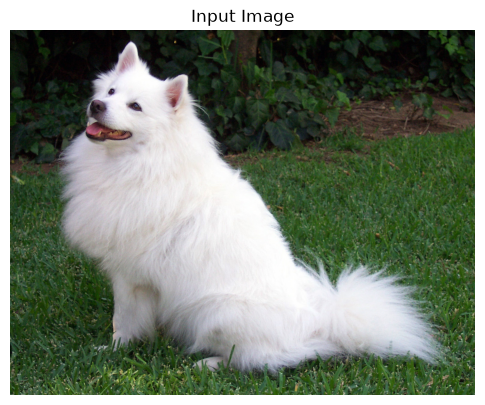

Image loaded successfully!
Image Size: (1546, 1213)


In [6]:
from pathlib import Path
from urllib.request import urlretrieve

# Create input directory
input_dir = Path("inputs")
input_dir.mkdir(exist_ok=True)

# Image URL
image_url = (
    "https://github.com/pytorch/hub/raw/master/images/dog.jpg"
)

image_path = input_dir / "dog.jpg"

# Download image if it does not already exist
if not image_path.exists():
    urlretrieve(image_url, image_path)

# Load image
image = Image.open(image_path).convert("RGB")

# Display image
plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.title("Input Image")
plt.axis("off")
plt.show()

print("Image loaded successfully!")
print("Image Size:", image.size)

In [7]:
# Get preprocessing transformations
preprocess = weights.transforms()

# Apply preprocessing
image_tensor = preprocess(image)

# Add batch dimension
input_tensor = image_tensor.unsqueeze(0)

# Move tensor to selected device
input_tensor = input_tensor.to(device)

print("Original Image Size:", image.size)
print("Processed Tensor Shape:", input_tensor.shape)
print("Tensor Data Type:", input_tensor.dtype)

Original Image Size: (1546, 1213)
Processed Tensor Shape: torch.Size([1, 3, 224, 224])
Tensor Data Type: torch.float32


In [8]:
# Perform prediction without calculating gradients
with torch.inference_mode():
    outputs = model(input_tensor)

# Convert model outputs into probabilities
probabilities = torch.nn.functional.softmax(
    outputs[0], dim=0
)

# Get top 5 predictions
top5_probabilities, top5_indices = torch.topk(
    probabilities, 5
)

# Get ImageNet class labels
categories = weights.meta["categories"]

print("Top 5 Image Classification Results:\n")

for i in range(5):
    class_name = categories[top5_indices[i].item()]
    confidence = top5_probabilities[i].item() * 100

    print(
        f"{i + 1}. {class_name}: {confidence:.2f}%"
    )

Top 5 Image Classification Results:

1. Samoyed: 88.46%
2. Arctic fox: 4.58%
3. white wolf: 4.43%
4. Pomeranian: 0.56%
5. Great Pyrenees: 0.47%


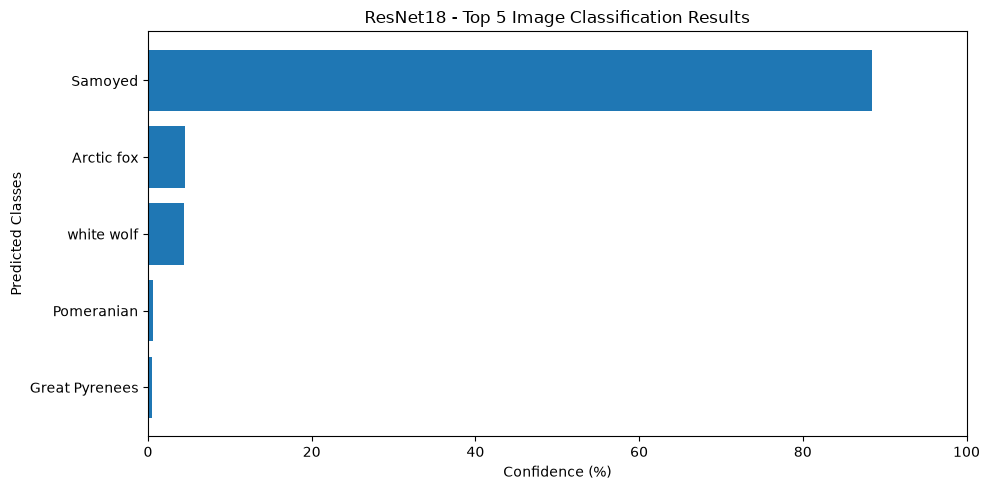

In [9]:
class_names = [
    categories[index.item()]
    for index in top5_indices
]

confidence_scores = [
    probability.item() * 100
    for probability in top5_probabilities
]

plt.figure(figsize=(10, 5))

plt.barh(class_names[::-1], confidence_scores[::-1])

plt.xlabel("Confidence (%)")
plt.ylabel("Predicted Classes")
plt.title("ResNet18 - Top 5 Image Classification Results")

plt.xlim(0, 100)
plt.tight_layout()
plt.show()

# Practical 2: CNN Visualization Using Grad-CAM

Aim: To visualize the important regions of an input image that influence a CNN model's classification decision using Grad-CAM (Gradient-weighted Class Activation Mapping).

Concepts covered:

- Explainable Artificial Intelligence (XAI)
- Model interpretability
- Convolutional Neural Networks
- Feature maps and gradients
- Grad-CAM heatmap generation
- Visualization of important image regions

## 1. Understanding Grad-CAM

### What is Explainable AI?

Deep learning models are often called black-box models because they can generate predictions without clearly explaining how they reached those decisions.

For example, a CNN might classify an image as a dog, but we may not know which part of the image influenced that prediction.

Explainable AI (XAI) helps us understand and interpret the decisions made by AI models.

### What is Grad-CAM?

Grad-CAM stands for Gradient-weighted Class Activation Mapping.

It is an Explainable AI technique used to highlight important regions of an image that contribute to a CNN's prediction.

Grad-CAM uses:

1. Feature maps generated by convolutional layers.
2. Gradients of the predicted class score.
3. Weighted combinations of feature maps.
4. A heatmap to highlight important image regions.

[How to Explain ConvNet Predictions Using Class Activation Maps | Pinecone](https://images.openai.com/static-rsc-4/CRmyKxwQ0tNU6DK7PJxzknV98rimpC8bKzzIDyeM1lFaCFMQV3cnR2Nuvj7Va0GidG_6k4J2FLKvtX4jtf4qc_pP8VRfVmTwHwFwiX6dz3MGXPW7Gvx8yxkmAh7PvJk9_6Mgh6e-5ljL6bLuuNawkqc-w6U3j-47eu-ek18gzNU?purpose=inline)

[GradCAM with TensorFlow: Interpreting Neural Networks with Class Activation Maps - Idiot Developer](https://images.openai.com/static-rsc-4/oEitj5wfHLE_S1YdbiyoR4HHSBClU7rQy-YinAAc_-fwYWZ5UTx7Ctd_1Wb7yiHcLDaOlFVN43G6N9iB8myCXnV5U5OSZ4m2lRmImKRtyv5NauTqHHgQzgpnzx-WQOc5V-0oyt8SFELH6c1VxYRDkwC81ZDGhdHNCKzJsywtQvM?purpose=inline)

[Class Active Mapping | Hello, Yeyang!](https://images.openai.com/static-rsc-4/L-6uQl9cbygRgduKw_3f19uwuMpxQIkUpOYJiXcxtee6NicpXlGO2UNU-v8GBvN_57XJvRV7e2zNWWnju7KwMbcAEUT2SR9jLFDYZjtgB3UJuYjCgjhTOCsQ3JvyJ42us4LDAOxqMI9w9uhAOeoXRv1W3qGgvafqV4nJ8aqwPiM?purpose=inline)

[How to Train Your ResNet: The Jindo Dog | by Thierry Laplanche | Analytics Vidhya | Medium](https://images.openai.com/static-rsc-4/sOujpmzSdeTX7IFGLw7XFhHBCy8MiKyWEF8-JhfvzkGAUyZYV2aqKs4mKnudiIDL6hX2DB8zw2m0_LskK4tgrGnBtzlqm6PhZqX2MJiEap2T90p_L2jx8VRqpLLgGohQLJe5nddUTAKPrt_TWCgfCjqG1MAbynXFJ7jBKenIJNY?purpose=inline)

[説明可能AI(XAI)の必要性と活用方法](https://images.openai.com/static-rsc-4/cRvWiwPlzv9p0qZGSThpl5LIgVXmO6D5SnhlFxesjrvHfRWanHKASBkPhnt7xLxZc0KWPV0AsG5-k7ElKnje76nX4KZOojqjr9XE-f9QRkT6HM2lnUTvJWi55PVoQ-ygN49IH0f8r-1XwdgTgQwcFaUFvq_mT69LVQFcUwmUlpc?purpose=inline)

[I trained a small U-Net-style model on the Oxford-IIIT Pet dataset and wanted to do more than just see if it got the right answer. | Tanner Norton](https://images.openai.com/static-rsc-4/L4SFwnQdbZkhrMwDqAryJAkE8P4vFDk7ge8nkBQ2Q0bHd1IKzZrSZXGiqLn5FS5Bo5B4HITnqO2F0uuBaAEXCvs9Q0PuXl7dLYpS4sqSlvutR3CUC_f4pul_-9KvsmRTgv71moj_QjU7yHkhZcUXX_u-hY3ZmWPNTxtsN1ZaN3o?purpose=inline)

[CAM, Grad-CAM và Score-CAM trong CNN](https://images.openai.com/static-rsc-4/T_vLqwI1AijTjAr4Ffi1_adMJQfUiIGKcbOmayaHT4nJtcs185kZvxKix3kgKAAUIYrf8B34MLr-8LkSYwb06yPWU5SfqESsfaowvCxaivMfgET6AETKgrifq4us6f9BoEqJelNyPj4gRCHHBgNUwPdRZnwEh2cZMWeokv0z9lU?purpose=inline)

[CAM类激活热力图的原理与模型可解释性应用-开发者社区-阿里云](https://images.openai.com/static-rsc-4/_XhMCc6l-I4yPxGOkheGqMhBfNEbK6N5OiteIkfUJ0UfI8d6__BiT4-_L0YKtdDX1ySLjtfX4WkxWSn6bP6mXrGU87Qkvp3awe65Au7myxaVbLhmQJ_B40D2MOS2jVKU3-UV-uDhBeKRkPNjor6MM1GCQu0Z8lUSbv2ma9HJSsU?purpose=inline)

### How does Grad-CAM work?

The process can be understood in five steps:

1. Pass an image through the CNN model.
2. Obtain the prediction score for a selected class.
3. Calculate gradients of that class score with respect to the selected convolutional layer's feature maps.
4. Calculate the importance weights using the average gradients.
5. Combine the feature maps and generate a heatmap.

The simplified Grad-CAM formula is:

\\[ \alpha_k^c = \frac{1}{Z}\sum_i\sum_j \frac{\partial y^c}{\partial A\_{ij}^k} \\]

\\[ L\_{\text{Grad-CAM}}^c = ReLU\left(\sum_k \alpha_k^c A^k\right) \\]

Where:

- \\(A^k\\) represents the feature map of the \\(k\\)-th channel.
- \\(y^c\\) represents the score of the predicted class.
- \\(\alpha_k^c\\) represents the importance weight.
- ReLU removes negative contributions.
- \\(L\_{\text{Grad-CAM}}^c\\) represents the final heatmap.



In [10]:
# Ensure the model is in evaluation mode
model.eval()

# Check existing variables
print("Model:", type(model).__name__)
print("Image:", image.size)
print("Input Tensor Shape:", input_tensor.shape)
print("Device:", device)

print("\nResNet18 is ready for Grad-CAM!")

Model: ResNet
Image: (1546, 1213)
Input Tensor Shape: torch.Size([1, 3, 224, 224])
Device: cpu

ResNet18 is ready for Grad-CAM!


In [11]:
# Select the target convolutional layer
target_layer = model.layer4[-1].conv2

print("Target Layer:")
print(target_layer)

Target Layer:
Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)


In [12]:
# Dictionaries to store activations and gradients
activations = {}
gradients = {}

# Function to capture feature maps
def forward_hook(module, inputs, output):
    activations["value"] = output

    # Capture gradients during backpropagation
    output.register_hook(
        lambda grad: gradients.__setitem__("value", grad)
    )

# Register forward hook
hook_handle = target_layer.register_forward_hook(
    forward_hook
)

print("Forward hook registered successfully!")

Forward hook registered successfully!


In [13]:
# Clear previous gradients
model.zero_grad()

# Forward pass
outputs = model(input_tensor)

# Get predicted class
predicted_class = outputs.argmax(dim=1).item()

# Get class name
categories = weights.meta["categories"]
predicted_label = categories[predicted_class]

# Select the predicted class score
class_score = outputs[0, predicted_class]

# Backpropagation
class_score.backward()

print("Predicted Class:", predicted_label)
print("Class Index:", predicted_class)

print("\nActivation Shape:", activations["value"].shape)
print("Gradient Shape:", gradients["value"].shape)

Predicted Class: Samoyed
Class Index: 258

Activation Shape: torch.Size([1, 512, 7, 7])
Gradient Shape: torch.Size([1, 512, 7, 7])


In [14]:
import torch.nn.functional as F

# Get feature maps and gradients
feature_maps = activations["value"]
gradient_values = gradients["value"]

# Calculate importance weights
weights_grad = gradient_values.mean(
    dim=(2, 3),
    keepdim=True
)

# Weighted combination of feature maps
cam = (weights_grad * feature_maps).sum(dim=1)

# Remove negative values
cam = torch.relu(cam)

# Resize heatmap to 224 x 224
cam = F.interpolate(
    cam.unsqueeze(1),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

# Normalize heatmap between 0 and 1
cam = cam.squeeze()

cam = cam - cam.min()
cam = cam / (cam.max() + 1e-8)

# Convert tensor to NumPy
heatmap = cam.detach().cpu().numpy()

print("Grad-CAM heatmap generated successfully!")
print("Heatmap Shape:", heatmap.shape)
print("Minimum Value:", heatmap.min())
print("Maximum Value:", heatmap.max())

Grad-CAM heatmap generated successfully!
Heatmap Shape: (224, 224)
Minimum Value: 0.0
Maximum Value: 1.0


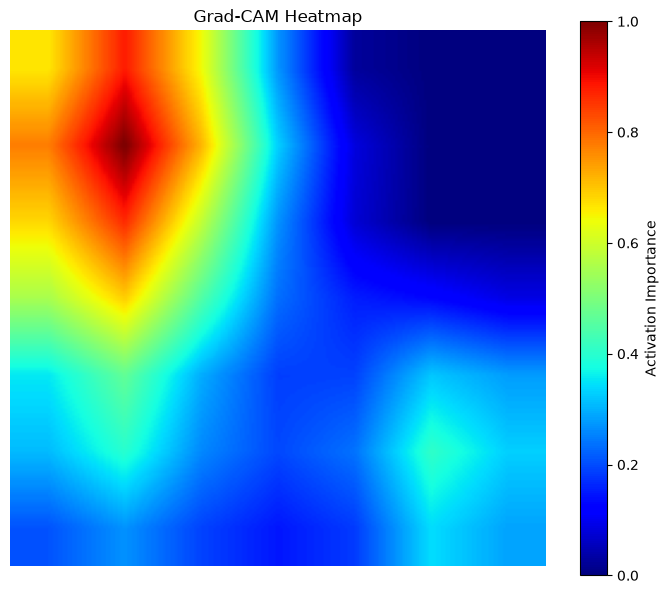

In [15]:
plt.figure(figsize=(7, 6))

plt.imshow(heatmap, cmap="jet")
plt.colorbar(label="Activation Importance")

plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.tight_layout()
plt.savefig(
    "outputs/GradCAMHeatmap.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

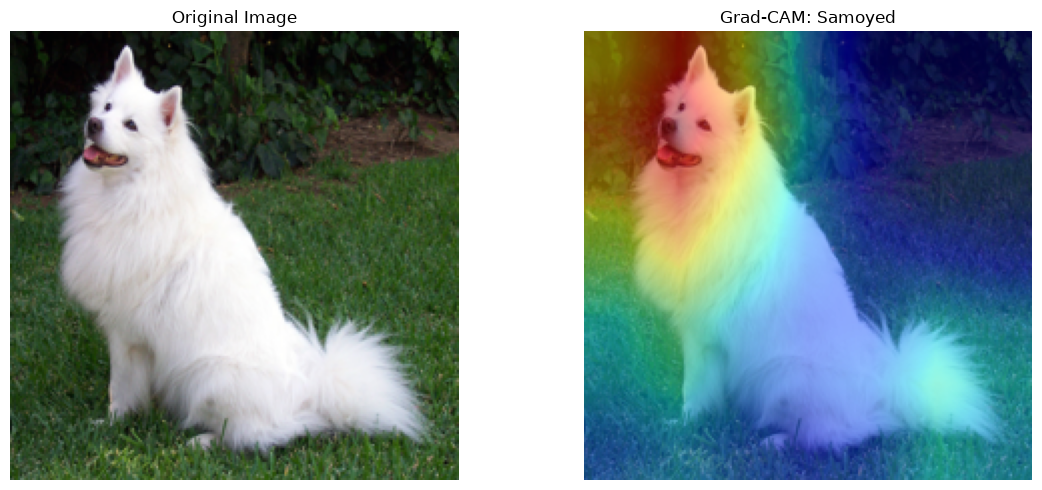

In [16]:
# Resize original image
original_image = image.resize((224, 224))

# Display original image and Grad-CAM overlay
plt.figure(figsize=(12, 5))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

# Heatmap overlay
plt.subplot(1, 2, 2)
plt.imshow(original_image)
plt.imshow(heatmap, cmap="jet", alpha=0.45)

plt.title(f"Grad-CAM: {predicted_label}")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    "outputs/GradCAMOverlay.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [17]:
hook_handle.remove()

print("Grad-CAM hook removed successfully!")
print("Practical 2 completed successfully!")

Grad-CAM hook removed successfully!
Practical 2 completed successfully!


# Practical 3: Adversarial Attack Using FGSM

Lab 7 · Experiment 3

Aim: To implement the Fast Gradient Sign Method (FGSM) attack on a pretrained ResNet18 model, generate adversarial images, and evaluate how small input perturbations can affect image classification.

Concepts covered:

- Adversarial Artificial Intelligence
- Adversarial examples
- Fast Gradient Sign Method (FGSM)
- Gradient-based attacks
- Image perturbation
- Model robustness evaluation

## 1. Understanding Adversarial AI

### What is Adversarial AI?

Adversarial AI studies how intentionally modified input data can influence or mislead an artificial intelligence model.

Sometimes, even a very small modification to an image can cause a deep learning model to make an incorrect prediction.

For example:

- Original image: Dog
- Original prediction: Golden Retriever
- Modified image: Slightly changed dog image
- Modified prediction: Different animal category

The modified image is called an adversarial example.

[From Attacker to Fixer:. When FGSM Doesn’t Break, It Builds | by Talex Maxim (taimax13) - #barracuda | Medium](https://images.openai.com/static-rsc-4/BukLBKjbsMTFOlKytpoS2CjJ6iBdH39SGd5re-xCzopA7SfjIJCBIlQi8f8JAYFgLtrtiHF3fo9qdQpQCovSf4HKrs7yLoh5Ws2XhQC9tZ1T56UAKdH79u3ypmbvhZ1ZFiR3uFlXZRE9SJcO_xSjdxV4QN5LJTb4wqtKvY1yEYk?purpose=inline)

[Evaluating the Robustness of Deep Learning Models against Adversarial Attacks: An Analysis with FGSM, PGD and CW](https://images.openai.com/static-rsc-4/1YIOuhWjUOsmofEoNrBNCP80I-RuAQ47pwIwA8WPrDKE7dpX0o55h_CUBDeSuaEWjyqGDBbWdC5XZeEIKVziDlR2z0s1t-wdNOJbiP8HH7rD4TCACPs3I1TLkANSdNF3H62fegK2Rj9TL--cVuZrqj6tW8CkUvecL0d20BmkIXM?purpose=inline)

[NeuroAI for AI safety - by Patrick Mineault](https://images.openai.com/static-rsc-4/NkA5nuzz3CauWNV9mBs3G7ht2D01C77cE5caT84mv0dvDSh2MwbYIjtX9fWA1qMwVXgk82ko9K-i5RUDLg9bC14ojLy7tii-zh4HB0AQxW-ifTeL3R7oQt8esRdDnnEvsLcAnb59qpbA0OYKKNnclwwBtfJuWSPwwxkL13o0NnQ?purpose=inline)

[Understanding Adversarial Attacks Through MNIST: CNN Vulnerability Guide - perfecXion.ai](https://images.openai.com/static-rsc-4/c-SZ-uMa08IBUwXE2QxKLMb2NgXFU0C_ySooydBjPiJ-0p-id8TZzQ5mPH4wjpS3QNM0CVGc2XYWOQ8ixYRrRLXZmPdN9zK_KxbQUy71xQiPzx79b0GrJ9nUavMaqdw1KPELYpKhxBo7GorCJWDNy5wPMy71mRzspOpjEohmIhU?purpose=inline)

[Adversarial attack](https://images.openai.com/static-rsc-4/nRCxO7qYOzKRxdJ-8RFPmHeNLbSGx_LoQMMpI0mvmxBzdaltNGO5jvw6TQacD14jgiRYSzpiITXazT6aOUY6Jv1UOtNMJ9S7EptrqvCpKr-U0pCapMwXifRpnOSYmcRp7dsJ3pGzcFZ6ybhLXu0p5OJRecJg6OYsBPZ26VZHXYY?purpose=inline)

[Evaluating the Robustness of Deep Learning Models against Adversarial Attacks: An Analysis with FGSM, PGD and CW](https://images.openai.com/static-rsc-4/thz2Nx-bDWEQUkhj7XHrBLz9HTRCVwGzbZxyU5in1qkk4RWCUygGsDrDRfn_yUNSv6CeD-s_Cs0yls-aBgKpgeMlfhkQm5DiwAZ_DmoByQHoEZ-iaxgYt4uzerC5t4-7zMGAXlSRHejMvLy0YOhujDQXU7EoaFUsPlrxOMEOv8w?purpose=inline)

[Securing (vision-based) autonomous systems: taxonomy, challenges, and defense mechanisms against adversarial threats | Artificial Intelligence Review | Springer Nature Link](https://images.openai.com/static-rsc-4/h6s_yoMl-lGFiWHn5HgeVr6EXWqITpu6X7iys8YtHT4NtcIQ9Q1dV55s8f1fBh0IejPXgx6HvqFsfyvbrHbB00dB4WRwv4-ttJREHbZETH5p5esVexXyuialuS0Dd_WNH6jYxSR4N_mL08jqVlXAY5o33BAvgc1IVWbSLJfHJwc?purpose=inline)

### What is FGSM?

FGSM stands for Fast Gradient Sign Method.

It is a gradient-based adversarial attack introduced to demonstrate how small changes in input pixels can affect neural network predictions.

FGSM calculates the gradient of the loss function with respect to the input image and uses its sign to determine the direction of perturbation.

The mathematical formula is:

\\[ x\_{adv}=x+\epsilon\cdot sign(\nabla_x J(\theta,x,y)) \\]

Where:

- \\(x\\) = Original input image.
- \\(x\_{adv}\\) = Adversarial image.
- \\(\epsilon\\) = Perturbation strength.
- \\(J\\) = Loss function.
- \\(\theta\\) = Model parameters.
- \\(y\\) = Correct class label.
- \\(\nabla_x J\\) = Gradient of loss with respect to input image.

In simple words: FGSM slightly changes image pixels in a direction that increases the model's classification loss.



In [18]:
# Ensure model is in evaluation mode
model.eval()

# Enable gradient calculation for the input image
original_tensor = preprocess(image).unsqueeze(0).to(device)

original_tensor.requires_grad = True

print("Model:", type(model).__name__)
print("Input Tensor Shape:", original_tensor.shape)
print("Device:", device)
print("FGSM environment ready!")

Model: ResNet
Input Tensor Shape: torch.Size([1, 3, 224, 224])
Device: cpu
FGSM environment ready!


In [19]:
# Clear model gradients
model.zero_grad()

# Original prediction
original_output = model(original_tensor)

# Get predicted class
original_class = original_output.argmax(dim=1).item()

# Get class name
categories = weights.meta["categories"]

original_label = categories[original_class]

# Calculate confidence
original_probabilities = torch.softmax(
    original_output, dim=1
)

original_confidence = (
    original_probabilities[0, original_class].item() * 100
)

print("Original Prediction:", original_label)
print(f"Original Confidence: {original_confidence:.2f}%")

Original Prediction: Samoyed
Original Confidence: 88.46%


In [20]:
# Use original predicted class as the label
target = torch.tensor(
    [original_class],
    device=device
)

# Calculate classification loss
criterion = torch.nn.CrossEntropyLoss()

# Clear previous gradients
model.zero_grad()

# Forward pass
output = model(original_tensor)

# Calculate loss
loss = criterion(output, target)

# Backpropagation
loss.backward()

# Extract input gradients
input_gradients = original_tensor.grad.data

print("Classification Loss:", loss.item())
print("Gradient Shape:", input_gradients.shape)
print("Gradient Calculation Completed!")

Classification Loss: 0.12259417772293091
Gradient Shape: torch.Size([1, 3, 224, 224])
Gradient Calculation Completed!


In [21]:
# Set perturbation strength
epsilon = 0.01

# Generate FGSM perturbation
perturbation = epsilon * input_gradients.sign()

# Create adversarial image
adversarial_tensor = original_tensor.detach() + perturbation

# Clamp values to valid normalized image range
mean = torch.tensor(
    weights.transforms().mean,
    device=device
).view(1, 3, 1, 1)

std = torch.tensor(
    weights.transforms().std,
    device=device
).view(1, 3, 1, 1)

minimum = (0 - mean) / std
maximum = (1 - mean) / std

adversarial_tensor = torch.maximum(
    torch.minimum(adversarial_tensor, maximum),
    minimum
)

print("FGSM Attack Generated Successfully!")
print("Epsilon:", epsilon)
print("Adversarial Tensor Shape:", adversarial_tensor.shape)

FGSM Attack Generated Successfully!
Epsilon: 0.01
Adversarial Tensor Shape: torch.Size([1, 3, 224, 224])


In [22]:
# Perform prediction on adversarial image
with torch.no_grad():
    adversarial_output = model(adversarial_tensor)

# Get adversarial prediction
adversarial_class = adversarial_output.argmax(dim=1).item()

adversarial_label = categories[adversarial_class]

# Calculate confidence
adversarial_probabilities = torch.softmax(
    adversarial_output, dim=1
)

adversarial_confidence = (
    adversarial_probabilities[0, adversarial_class].item() * 100
)

print("Original Prediction:", original_label)
print("Adversarial Prediction:", adversarial_label)

print(f"\nOriginal Confidence: {original_confidence:.2f}%")
print(f"Adversarial Confidence: {adversarial_confidence:.2f}%")

if adversarial_class != original_class:
    print("\nResult: Adversarial attack changed the prediction!")
else:
    print("\nResult: Prediction remained unchanged.")

Original Prediction: Samoyed
Adversarial Prediction: Arctic fox

Original Confidence: 88.46%
Adversarial Confidence: 51.32%

Result: Adversarial attack changed the prediction!


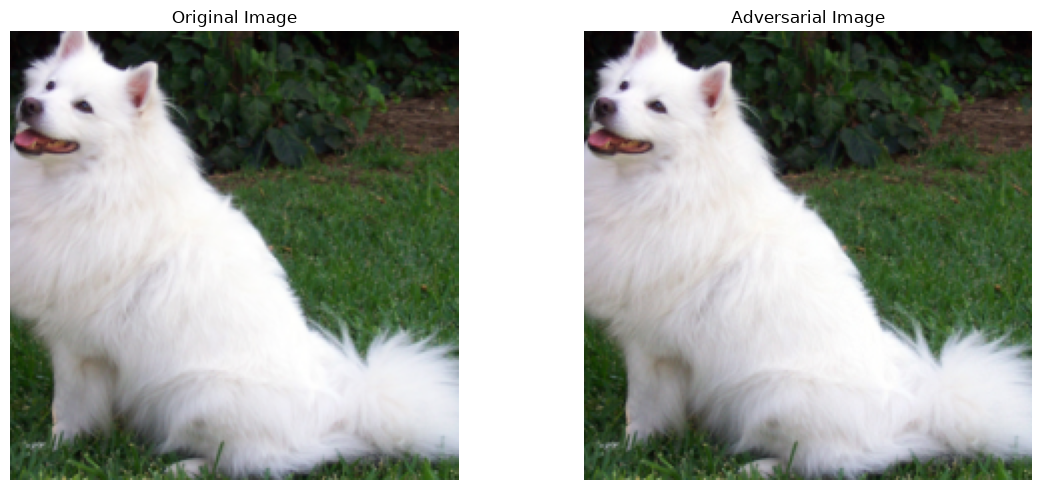

In [23]:
def tensor_to_image(tensor):
    # Move tensor to CPU
    tensor = tensor.detach().cpu().squeeze(0)

    # Reverse normalization
    mean = torch.tensor(
        weights.transforms().mean
    ).view(3, 1, 1)

    std = torch.tensor(
        weights.transforms().std
    ).view(3, 1, 1)

    tensor = tensor * std + mean

    # Convert values into valid image range
    tensor = tensor.clamp(0, 1)

    # Convert tensor to NumPy image
    array = tensor.permute(1, 2, 0).numpy()

    return array


original_display = tensor_to_image(original_tensor)
adversarial_display = tensor_to_image(adversarial_tensor)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_display)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(adversarial_display)
plt.title("Adversarial Image")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    "outputs/FGSMImageComparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

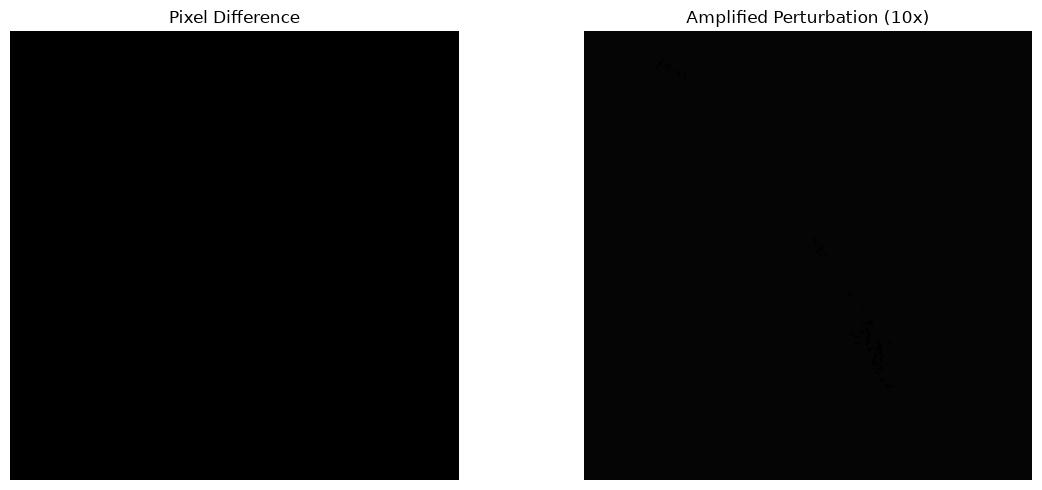

In [24]:
# Calculate absolute pixel difference
difference = np.abs(
    original_display - adversarial_display
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(difference)
plt.title("Pixel Difference")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(difference * 10)
plt.title("Amplified Perturbation (10x)")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    "outputs/FGSMPerturbation.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [25]:
epsilon_values = [0.0, 0.01, 0.03, 0.05, 0.1]

results = []

for eps in epsilon_values:

    # Generate adversarial image for current epsilon
    adv_tensor = original_tensor.detach() + (
        eps * input_gradients.sign()
    )

    # Clamp to normalized pixel range
    adv_tensor = torch.maximum(
        torch.minimum(adv_tensor, maximum),
        minimum
    )

    # Predict
    with torch.no_grad():
        prediction = model(adv_tensor)

    probabilities = torch.softmax(prediction, dim=1)

    predicted_index = prediction.argmax(dim=1).item()

    confidence = (
        probabilities[0, predicted_index].item() * 100
    )

    predicted_name = categories[predicted_index]

    results.append({
        "Epsilon": eps,
        "Prediction": predicted_name,
        "Confidence": confidence,
        "Changed": predicted_index != original_class
    })

# Display results
for result in results:
    print(
        f"Epsilon: {result['Epsilon']:.2f} | "
        f"Prediction: {result['Prediction']} | "
        f"Confidence: {result['Confidence']:.2f}% | "
        f"Changed: {result['Changed']}"
    )

Epsilon: 0.00 | Prediction: Samoyed | Confidence: 88.46% | Changed: False
Epsilon: 0.01 | Prediction: Arctic fox | Confidence: 51.32% | Changed: True
Epsilon: 0.03 | Prediction: Arctic fox | Confidence: 45.71% | Changed: True
Epsilon: 0.05 | Prediction: Arctic fox | Confidence: 35.91% | Changed: True
Epsilon: 0.10 | Prediction: Arctic fox | Confidence: 36.30% | Changed: True


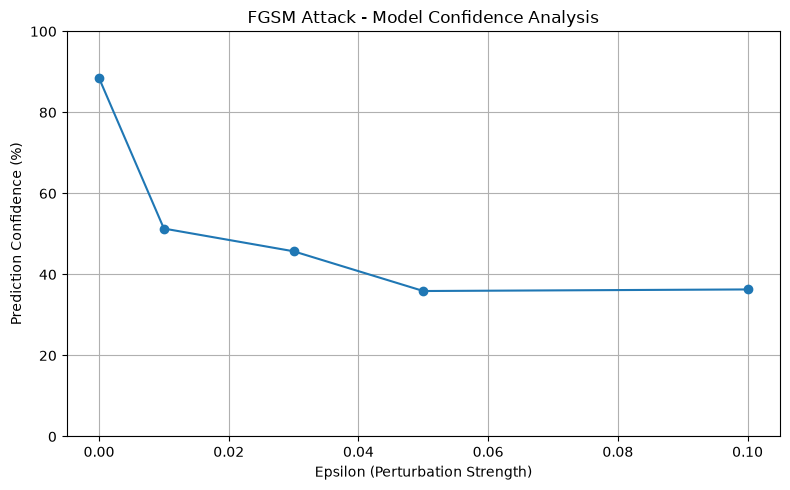

In [26]:
epsilon_list = [
    result["Epsilon"] for result in results
]

confidence_list = [
    result["Confidence"] for result in results
]

plt.figure(figsize=(8, 5))

plt.plot(
    epsilon_list,
    confidence_list,
    marker="o"
)

plt.xlabel("Epsilon (Perturbation Strength)")
plt.ylabel("Prediction Confidence (%)")

plt.title("FGSM Attack - Model Confidence Analysis")

plt.ylim(0, 100)
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "outputs/FGSMRobustnessGraph.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# Practical 4: PCA for Dimensionality Reduction

Aim: To implement Principal Component Analysis (PCA) using Python and Scikit-learn to reduce the dimensionality of a dataset while retaining as much important information as possible.

Concepts covered:

- Dimensionality reduction
- Principal Component Analysis (PCA)
- Feature scaling and standardization
- Explained variance
- Principal components
- Two-dimensional data visualization

## 1. Understanding PCA

### What is dimensionality reduction?

A dataset may contain many features (columns). When the number of features becomes very large, analyzing and visualizing the data becomes difficult.

Dimensionality reduction is a technique used to reduce the number of features while preserving as much useful information as possible.

For example:

A student dataset might contain:

- Mathematics marks
- Science marks
- English marks
- Computer marks
- Attendance
- Study hours

Instead of working with all six features, dimensionality reduction can transform them into two new features called principal components.

### What is PCA?

PCA stands for Principal Component Analysis.

It is an unsupervised dimensionality reduction technique that transforms correlated numerical features into a smaller set of new, uncorrelated variables called principal components.

The first principal component captures the maximum possible variance in the data. The second captures the maximum remaining variance while being perpendicular to the first, and so on.

[Derivation of Principal Component Analysis | by sako | Medium](https://images.openai.com/static-rsc-4/06Lt-7LIE6enPTTU6Bvxxl7lE8fcv4aajvjfFMXZRS41eVoZLH39SW6vr8z0O-flzLQKOYnf76ApMT89jspYT7MeN1RI0r-VIc77FU0Jy7C4vrTpdTiq9YVC6u5GZc0bMaab7tfqtHTRmNp3oHD105oz3BUc0a7NAKtiX6nmdHM?purpose=inline)

[medium.com](https://medium.com/%40seimaosako/derivation-of-principal-component-analysis-acc6bfb31161?utm_source=chatgpt.com)

### Important PCA terminology

| Term                     | Meaning                                          |
| ------------------------ | ------------------------------------------------ |
| Variance                 | Measures how much data values are spread out     |
| Principal Component      | A new feature created by PCA                     |
| Explained Variance       | Amount of data variation captured by a component |
| Explained Variance Ratio | Proportion of total variance captured            |
| Standardization          | Scaling features to comparable ranges            |

PCA formula:

\\[ Z = XW \\]

Where:

- \\(X\\) = Standardized input dataset.
- \\(W\\) = Principal component directions (eigenvectors).
- \\(Z\\) = Transformed dataset with reduced dimensions.



In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("Libraries imported successfully!")

Libraries imported successfully!


In [28]:
# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df["Species"] = iris.target

# Display dataset
print("First 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nSpecies:")
print(iris.target_names)

First 5 Rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Species  
0        0  
1        0  
2        0  
3        0  
4        0  

Dataset Shape: (150, 5)

Species:
['setosa' 'versicolor' 'virginica']


In [29]:
# Select numerical features
X = iris.data

# Select target labels
y = iris.target

print("Feature Matrix Shape:", X.shape)
print("Target Array Shape:", y.shape)

print("\nFeature Names:")
print(iris.feature_names)

Feature Matrix Shape: (150, 4)
Target Array Shape: (150,)

Feature Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [30]:
# Create StandardScaler
scaler = StandardScaler()

# Standardize features
X_scaled = scaler.fit_transform(X)

print("Original Dataset Shape:", X.shape)
print("Standardized Dataset Shape:", X_scaled.shape)

print("\nStandardized First 5 Rows:")
print(X_scaled[:5])

print("\nFeature Means:")
print(X_scaled.mean(axis=0).round(2))

Original Dataset Shape: (150, 4)
Standardized Dataset Shape: (150, 4)

Standardized First 5 Rows:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]

Feature Means:
[-0. -0. -0. -0.]


In [31]:
# Create PCA with 2 components
pca = PCA(n_components=2)

# Transform standardized data
X_pca = pca.fit_transform(X_scaled)

print("Original Feature Dimensions:", X_scaled.shape[1])
print("Reduced Feature Dimensions:", X_pca.shape[1])

print("\nPCA Transformed Data:")
print(X_pca[:5])

Original Feature Dimensions: 4
Reduced Feature Dimensions: 2

PCA Transformed Data:
[[-2.26470281  0.4800266 ]
 [-2.08096115 -0.67413356]
 [-2.36422905 -0.34190802]
 [-2.29938422 -0.59739451]
 [-2.38984217  0.64683538]]


In [32]:
# Get explained variance ratios
variance_ratio = pca.explained_variance_ratio_

# Calculate cumulative variance
cumulative_variance = np.cumsum(variance_ratio)

print("Explained Variance Ratio:")

for i, value in enumerate(variance_ratio):
    print(f"PC{i + 1}: {value:.4f} ({value * 100:.2f}%)")

print(
    "\nTotal Variance Retained:",
    f"{sum(variance_ratio) * 100:.2f}%"
)

Explained Variance Ratio:
PC1: 0.7296 (72.96%)
PC2: 0.2285 (22.85%)

Total Variance Retained: 95.81%


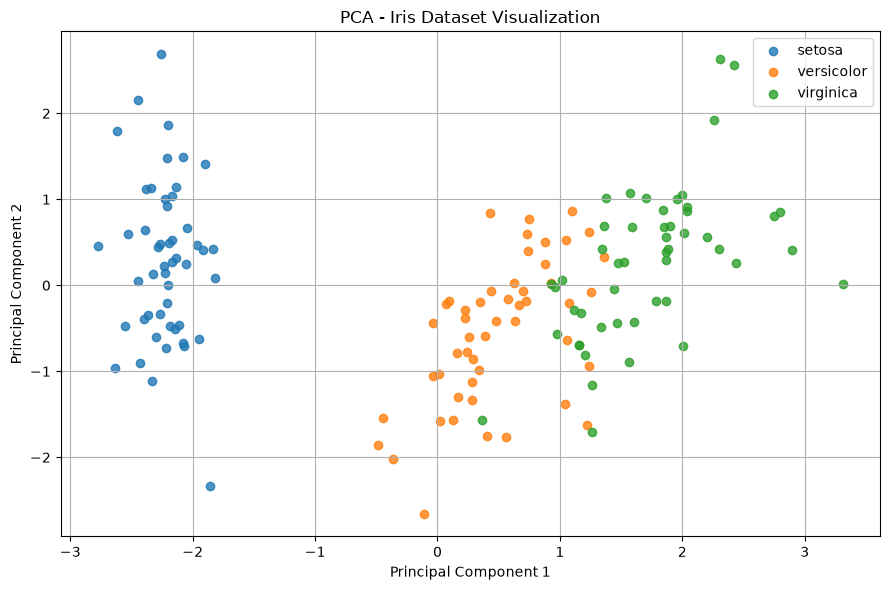

In [33]:
plt.figure(figsize=(9, 6))

for species_id, species_name in enumerate(iris.target_names):

    plt.scatter(
        X_pca[y == species_id, 0],
        X_pca[y == species_id, 1],
        label=species_name,
        alpha=0.8
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA - Iris Dataset Visualization")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "outputs/PCAScatterPlot.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

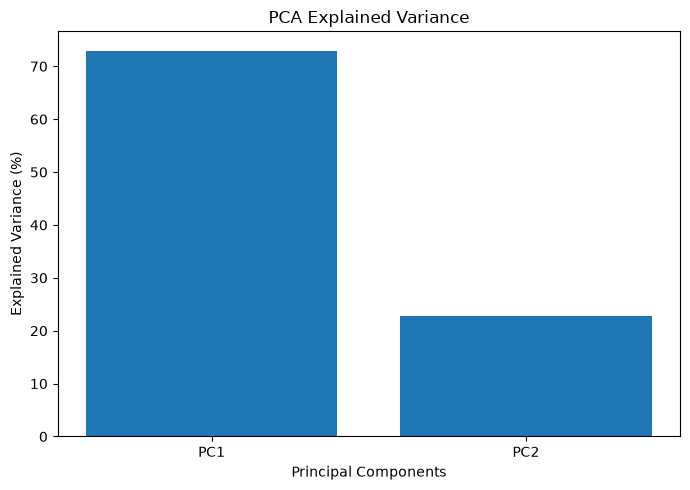

In [34]:
components = ["PC1", "PC2"]

plt.figure(figsize=(7, 5))

plt.bar(
    components,
    variance_ratio * 100
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")

plt.title("PCA Explained Variance")

plt.tight_layout()

plt.savefig(
    "outputs/PCAExplainedVarianceGraph.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [35]:
print("PCA Dimensionality Reduction Summary")
print("------------------------------------")

print("Original Features:", X.shape[1])
print("Reduced Features:", X_pca.shape[1])

print("Original Samples:", X.shape[0])
print("Reduced Samples:", X_pca.shape[0])

print(
    "Information Retained:",
    f"{sum(variance_ratio) * 100:.2f}%"
)

print(
    "Dimensions Reduced By:",
    X.shape[1] - X_pca.shape[1]
)

PCA Dimensionality Reduction Summary
------------------------------------
Original Features: 4
Reduced Features: 2
Original Samples: 150
Reduced Samples: 150
Information Retained: 95.81%
Dimensions Reduced By: 2


# Practical 5: Mini Project: Explainable Image Classification

Lab 7 · Final Experiment

Aim: To develop an Explainable Image Classification system using a pretrained ResNet18 model, Grad-CAM visualization, and FGSM adversarial attack to understand image classification, model interpretability, and model robustness.

This mini-project combines the concepts implemented in the previous three practicals into one complete application.

## 1. Project overview

### Problem statement

Deep learning models can classify images accurately, but understanding their decisions and evaluating their reliability are equally important.

This project develops an image classification system that:

1. Identifies objects in an input image using ResNet18.
2. Explains predictions using Grad-CAM heatmaps.
3. Generates adversarial images using FGSM.
4. Compares original and adversarial predictions.
5. Evaluates model confidence under different perturbation strengths.

### Technologies used

| Technology  | Purpose                 |
| ----------- | ----------------------- |
| Python      | Programming language    |
| PyTorch     | Deep learning framework |
| Torchvision | Pretrained ResNet18     |
| NumPy       | Numerical operations    |
| Matplotlib  | Image visualization     |
| Pillow      | Image processing        |

### System architecture

[How explainable are adversarially-robust cnns? | Academic](https://images.openai.com/static-rsc-4/mdw4VrhhW7p8sNj651MArOMJz0S411T8NNKFEjOviGnw_7S3sJRlVY40zbmhVrCmKw8iSWY6_9GHxat5KLgRPwBfMX6yaeubDGL4nGpIykf8U1E_yaM5wKzaQuoH0-DNA1e-pB6ZITJNdVLozlxWSUaDN82LS-fhuJiqGReFDkY?purpose=inline)

[chanfeechen.github.io](https://chanfeechen.github.io/resume/project/xai_robustness/?utm_source=chatgpt.com)

The system follows this workflow:

```
             Input Image
                  |
                  v
             ResNet18
                  |
                  v
         Original Prediction
                  |
          +-------+-------+
          |               |
          v               v
       Grad-CAM          FGSM
          |               |
          v               v
     Heatmap         Adversarial Image
                          |
                          v
                   New Prediction
                          |
                          v
                  Robustness Analysis
```



In [36]:
from pathlib import Path

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

# Create output directory
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Load existing image
image = Image.open("inputs/dog.jpg").convert("RGB")

# Ensure model is in evaluation mode
model.eval()

# Prepare image tensor
input_tensor = preprocess(image).unsqueeze(0).to(device)

print("Mini Project Environment Ready!")
print("Image Size:", image.size)
print("Model:", type(model).__name__)
print("Device:", device)

Mini Project Environment Ready!
Image Size: (1546, 1213)
Model: ResNet
Device: cpu


In [37]:
# Perform image classification
with torch.inference_mode():
    original_output = model(input_tensor)

# Get predicted class
original_class = original_output.argmax(dim=1).item()

# Convert scores into probabilities
original_probabilities = torch.softmax(
    original_output, dim=1
)

# Get predicted category
categories = weights.meta["categories"]

original_label = categories[original_class]

original_confidence = (
    original_probabilities[0, original_class].item() * 100
)

print("Original Image Classification")
print("--------------------------------")

print("Predicted Class:", original_label)
print(f"Confidence: {original_confidence:.2f}%")

Original Image Classification
--------------------------------
Predicted Class: Samoyed
Confidence: 88.46%


In [38]:
# Dictionaries to store feature maps and gradients
activations = {}
gradients = {}

# Select final convolutional layer
target_layer = model.layer4[-1].conv2

# Capture feature maps
def forward_hook(module, inputs, output):
    activations["value"] = output

    output.register_hook(
        lambda grad: gradients.__setitem__("value", grad)
    )

# Register hook
hook_handle = target_layer.register_forward_hook(
    forward_hook
)

# Enable gradients
grad_input = input_tensor.clone().detach()
grad_input.requires_grad = True

# Forward pass
model.zero_grad()

grad_output = model(grad_input)

# Select original predicted class score
class_score = grad_output[0, original_class]

# Backpropagation
class_score.backward()

# Get activations and gradients
feature_maps = activations["value"]
gradient_values = gradients["value"]

# Calculate channel importance
importance_weights = gradient_values.mean(
    dim=(2, 3),
    keepdim=True
)

# Generate Grad-CAM
cam = torch.relu(
    (importance_weights * feature_maps).sum(dim=1)
)

# Resize heatmap
cam = F.interpolate(
    cam.unsqueeze(1),
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

# Normalize heatmap
cam = cam.squeeze().detach()

cam = cam - cam.min()
cam = cam / (cam.max() + 1e-8)

heatmap = cam.cpu().numpy()

# Remove hook
hook_handle.remove()

print("Grad-CAM generated successfully!")
print("Heatmap Shape:", heatmap.shape)

Grad-CAM generated successfully!
Heatmap Shape: (224, 224)


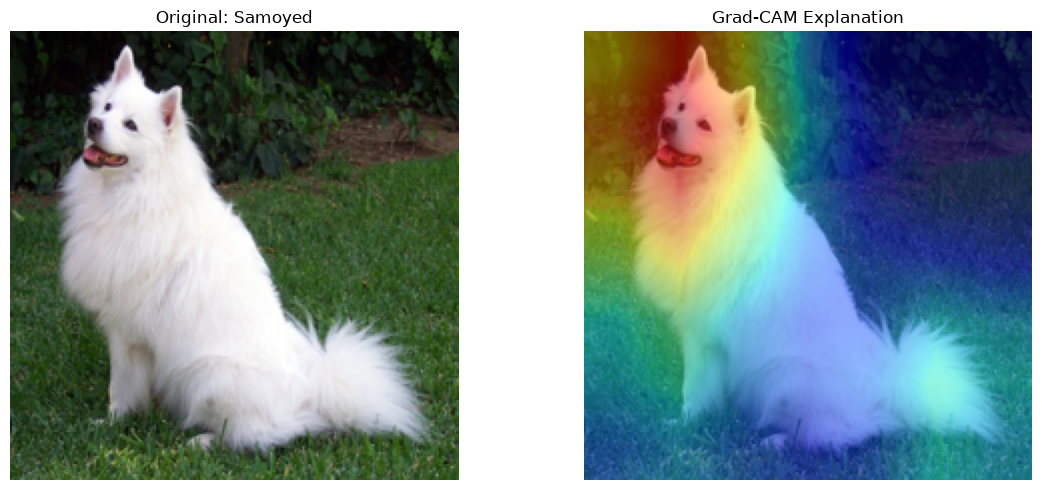

In [39]:
# Resize original image
original_display = image.resize((224, 224))

plt.figure(figsize=(12, 5))

# Original image
plt.subplot(1, 2, 1)
plt.imshow(original_display)
plt.title(f"Original: {original_label}")
plt.axis("off")

# Grad-CAM visualization
plt.subplot(1, 2, 2)
plt.imshow(original_display)
plt.imshow(heatmap, cmap="jet", alpha=0.45)

plt.title("Grad-CAM Explanation")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    output_dir / "MiniProjectGradCAM.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [40]:
# Create input tensor with gradient tracking
attack_input = input_tensor.clone().detach()
attack_input.requires_grad = True

# Calculate original class loss
model.zero_grad()

attack_output = model(attack_input)

target = torch.tensor(
    [original_class],
    device=device
)

criterion = torch.nn.CrossEntropyLoss()

loss = criterion(attack_output, target)

# Calculate input gradients
loss.backward()

input_gradients = attack_input.grad.data

# FGSM perturbation strength
epsilon = 0.01

# Generate perturbation
perturbation = epsilon * input_gradients.sign()

# Create adversarial tensor
adversarial_tensor = (
    attack_input.detach() + perturbation
)

# Normalized image limits
mean = torch.tensor(
    weights.transforms().mean,
    device=device
).view(1, 3, 1, 1)

std = torch.tensor(
    weights.transforms().std,
    device=device
).view(1, 3, 1, 1)

minimum = (0 - mean) / std
maximum = (1 - mean) / std

# Clamp values
adversarial_tensor = torch.maximum(
    torch.minimum(adversarial_tensor, maximum),
    minimum
)

print("Adversarial Image Generated!")
print("Epsilon:", epsilon)
print("Loss:", loss.item())

Adversarial Image Generated!
Epsilon: 0.01
Loss: 0.12259417772293091


In [41]:
# Predict adversarial image
with torch.inference_mode():
    adversarial_output = model(adversarial_tensor)

# Get predicted class
adversarial_class = adversarial_output.argmax(dim=1).item()

# Calculate probabilities
adversarial_probabilities = torch.softmax(
    adversarial_output, dim=1
)

adversarial_label = categories[adversarial_class]

adversarial_confidence = (
    adversarial_probabilities[0, adversarial_class].item() * 100
)

print("Classification Comparison")
print("--------------------------------")

print("Original Prediction:", original_label)
print("Adversarial Prediction:", adversarial_label)

print(f"Original Confidence: {original_confidence:.2f}%")
print(f"Adversarial Confidence: {adversarial_confidence:.2f}%")

if original_class != adversarial_class:
    print("\nAttack Result: Prediction successfully changed!")
else:
    print("\nAttack Result: Original prediction remained unchanged.")

Classification Comparison
--------------------------------
Original Prediction: Samoyed
Adversarial Prediction: Arctic fox
Original Confidence: 88.46%
Adversarial Confidence: 51.32%

Attack Result: Prediction successfully changed!


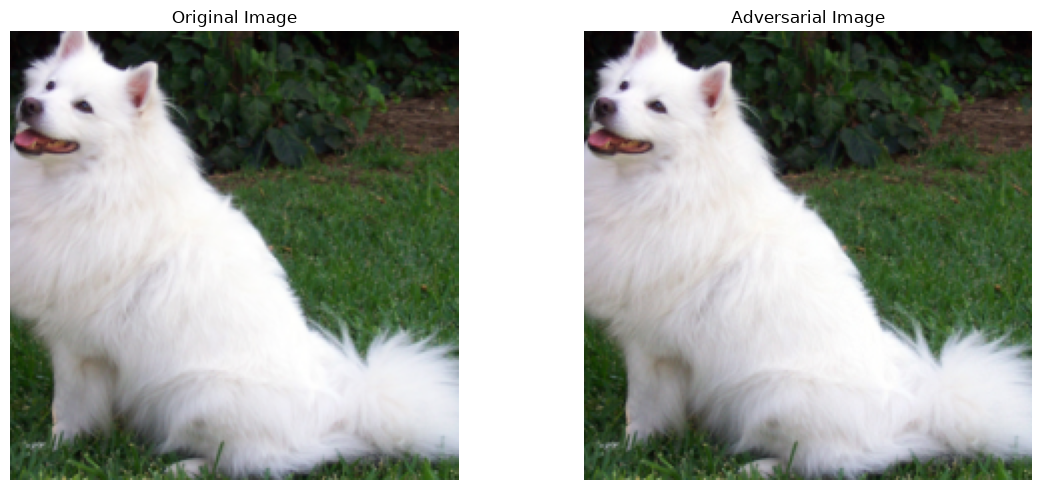

In [42]:
def convert_tensor_to_image(tensor):

    tensor = tensor.detach().cpu().squeeze(0)

    mean_cpu = torch.tensor(
        weights.transforms().mean
    ).view(3, 1, 1)

    std_cpu = torch.tensor(
        weights.transforms().std
    ).view(3, 1, 1)

    tensor = tensor * std_cpu + mean_cpu

    tensor = tensor.clamp(0, 1)

    return tensor.permute(1, 2, 0).numpy()


original_image_array = convert_tensor_to_image(input_tensor)

adversarial_image_array = convert_tensor_to_image(
    adversarial_tensor
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image_array)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(adversarial_image_array)
plt.title("Adversarial Image")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    output_dir / "MiniProjectImageComparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [43]:
epsilon_values = [0.0, 0.01, 0.03, 0.05, 0.1]

robustness_results = []

for eps in epsilon_values:

    # Generate adversarial input
    adv_input = input_tensor.detach() + (
        eps * input_gradients.sign()
    )

    # Clamp normalized values
    adv_input = torch.maximum(
        torch.minimum(adv_input, maximum),
        minimum
    )

    # Predict
    with torch.inference_mode():
        prediction = model(adv_input)

    probabilities = torch.softmax(
        prediction, dim=1
    )

    predicted_index = prediction.argmax(dim=1).item()

    confidence = (
        probabilities[0, predicted_index].item() * 100
    )

    robustness_results.append({
        "Epsilon": eps,
        "Prediction": categories[predicted_index],
        "Confidence": confidence,
        "Changed": predicted_index != original_class
    })


# Display results
print("Model Robustness Evaluation")
print("--------------------------------")

for result in robustness_results:

    print(
        f"Epsilon: {result['Epsilon']:.2f} | "
        f"Prediction: {result['Prediction']} | "
        f"Confidence: {result['Confidence']:.2f}% | "
        f"Changed: {result['Changed']}"
    )

Model Robustness Evaluation
--------------------------------
Epsilon: 0.00 | Prediction: Samoyed | Confidence: 88.46% | Changed: False
Epsilon: 0.01 | Prediction: Arctic fox | Confidence: 51.32% | Changed: True
Epsilon: 0.03 | Prediction: Arctic fox | Confidence: 45.71% | Changed: True
Epsilon: 0.05 | Prediction: Arctic fox | Confidence: 35.91% | Changed: True
Epsilon: 0.10 | Prediction: Arctic fox | Confidence: 36.30% | Changed: True


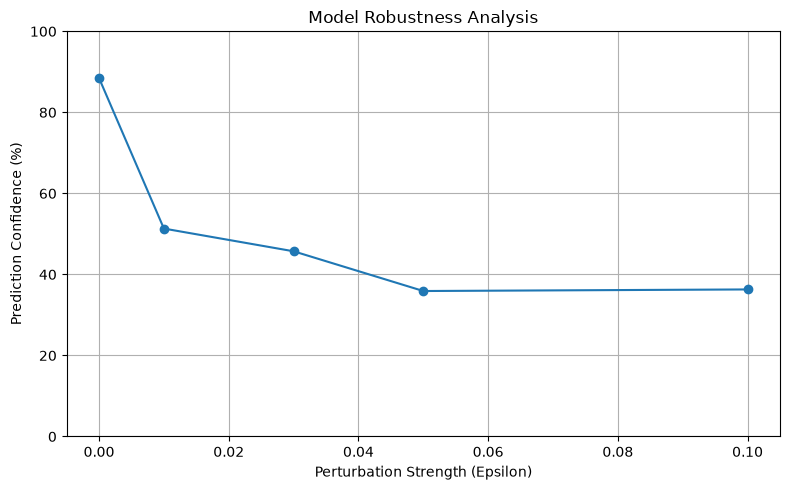

In [44]:
epsilon_list = [
    result["Epsilon"]
    for result in robustness_results
]

confidence_list = [
    result["Confidence"]
    for result in robustness_results
]

plt.figure(figsize=(8, 5))

plt.plot(
    epsilon_list,
    confidence_list,
    marker="o"
)

plt.xlabel("Perturbation Strength (Epsilon)")
plt.ylabel("Prediction Confidence (%)")

plt.title("Model Robustness Analysis")

plt.ylim(0, 100)
plt.grid(True)
plt.tight_layout()

plt.savefig(
    output_dir / "MiniProjectRobustnessGraph.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()